# 03. Симуляції: чи можна довіряти нашій процедурі

Крок 7 плану. **Усі дані в цьому ноутбуці синтетичні:** їх згенеровано в numpy. Із реального експерименту взято лише параметри: базові конверсії та розмір групи.

1. A/A-тести: чи справді хибні «перемоги» трапляються у 5% випадків.
2. Peeking: що буде, якщо дивитися на результат по ходу тесту й зупинитись на першому p < 0,05.
3. Множинні порівняння: 20 метрик без ефекту.
4. Power: симуляція проти формули з кроку 6.
5. SRM: що робить зламана рандомізація (опційний пункт).

Функції в `src/simulations.py`, тести в `tests/test_simulations.py`. Seed зафіксовано, тому результати відтворюються.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import ab_stats as ab
import simulations as sim

real = pd.read_csv(ROOT / "results" / "04_conversion_by_group.csv").set_index("segment")
P_ALL = real.buyers.sum() / real.n.sum()                                   # overall conversion
P_CONTROL = real.loc["No E-Mail", "buyers"] / real.loc["No E-Mail", "n"]   # baseline used in step 6
N = 21_300                                                                 # clients per group
ALPHA = 0.05
print(f"overall conversion {P_ALL:.5f}, control conversion {P_CONTROL:.5f}, n per group {N}")

BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"
INK, MUTED, GRID = "#191919", "#666666", "#e7e7e7"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c2c2c2", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 12,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
    "legend.frameon": False,
})

overall conversion 0.00903, control conversion 0.00573, n per group 21300


## 1. A/A-симуляція: 1000 тестів без жодної різниці

Обидві групи мають однакову конверсію (≈ 0,9%) і по 21 300 клієнтів. Кожне «значуще» тут хибне.
Дані кожного тесту надходять 100 порціями по 213 клієнтів на групу: фінальний результат дає звичайний A/A-тест, а проміжні знадобляться в розділі 2.

Конверсії є цілими числами, тому p-value дискретний, і навіть на мільйонах тестів гістограма не буде ідеально плоскою. Тому плоскість перевіряємо двічі: проти рівних часток і проти часток, отриманих на 2 000 000 симуляцій тих самих параметрів.

share p < 0.05: 5.7%  (95% Monte Carlo CI 4.3% .. 7.3%)
chi-square over 20 bins vs equal shares:             p = 0.012
chi-square over 20 bins vs expected discrete shares: p = 0.308
2 000 000 tests: share p < 0.05 = 4.99%, bin shares 4.0% .. 6.3%


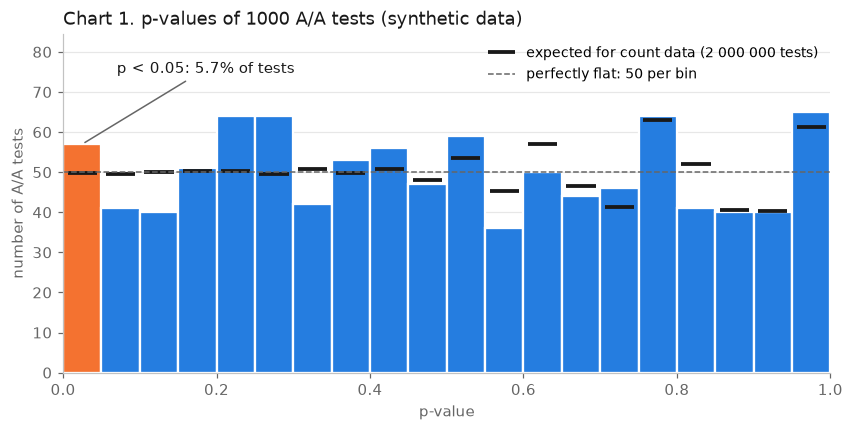

In [2]:
N_SIM, N_BATCHES = 1000, 100
running = sim.running_pvalues(np.random.default_rng(42), P_ALL, N // N_BATCHES, N_BATCHES, N_SIM)
aa_p = running[:, -1]

share = (aa_p < ALPHA).mean()
mc = stats.binomtest(int((aa_p < ALPHA).sum()), N_SIM).proportion_ci()
bins = np.linspace(0, 1, 21)
hist, _ = np.histogram(aa_p, bins)
uniform_p = stats.chisquare(hist).pvalue

big = np.random.default_rng(0)
big_p = sim.two_proportion_pvalues(big.binomial(N, P_ALL, 2_000_000), N, big.binomial(N, P_ALL, 2_000_000), N)
expected_share = np.histogram(big_p, bins)[0] / len(big_p)
discrete_p = stats.chisquare(hist, expected_share * N_SIM).pvalue
print(f"share p < 0.05: {share:.1%}  (95% Monte Carlo CI {mc.low:.1%} .. {mc.high:.1%})")
print(f"chi-square over 20 bins vs equal shares:             p = {uniform_p:.3f}")
print(f"chi-square over 20 bins vs expected discrete shares: p = {discrete_p:.3f}")
print(f"2 000 000 tests: share p < 0.05 = {(big_p < ALPHA).mean():.2%}, bin shares {expected_share.min():.1%} .. {expected_share.max():.1%}")

fig, ax = plt.subplots(figsize=(9, 4))
colors = [ORANGE] + [BLUE] * 19
ax.bar(bins[:-1], hist, width=0.05, align="edge", color=colors, edgecolor="white", linewidth=1.5)
ax.hlines(expected_share * N_SIM, bins[:-1] + 0.006, bins[1:] - 0.006, color=INK, linewidth=2.5,
          label="expected for count data (2 000 000 tests)")
ax.axhline(N_SIM / 20, color=MUTED, linewidth=1, linestyle="--", label="perfectly flat: 50 per bin")
ax.legend(loc="upper right", fontsize=9)
ax.annotate(f"p < 0.05: {share:.1%} of tests", xy=(0.025, hist[0]), xytext=(0.07, hist.max() * 1.15),
            color=INK, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set(xlim=(0, 1), ylim=(0, hist.max() * 1.3), xlabel="p-value", ylabel="number of A/A tests",
       title="Chart 1. p-values of 1000 A/A tests (synthetic data)")
plt.show()

**Висновок:** хибна «перемога» трапилась у 5,7% A/A-тестів (95% Монте-Карло ДІ 4,3–7,3%, тобто узгоджується з обіцяними 5%), а нерівність стовпчиків пояснюється дискретністю p-value і випадковістю: проти очікуваного дискретного розподілу chi-square дає p = 0,31 (проти ідеально плоского p = 0,012, але це порівняння тут некоректне).

## 2. Peeking: підглядання з ранньою зупинкою

Беремо **ті самі** 1000 тестів. Тепер аналітик перевіряє p-value кілька разів з рівним кроком і оголошує перемогу, щойно p < 0,05. Для порівняння: та сама схема, але з порогом 0,05 / кількість переглядів (Bonferroni по переглядах).

 looks  every_n_per_group naive_alpha_005 alpha_divided_by_looks
     1              21300            5.7%                   5.7%
     2              10650            8.7%                   5.0%
     4               5325           13.0%                   4.2%
     5               4260           15.0%                   3.9%
    10               2130           18.7%                   2.6%
    20               1065           23.9%                   2.2%
    25                852           26.3%                   1.7%
    50                426           31.4%                   0.9%
   100                213           36.2%                   0.6%


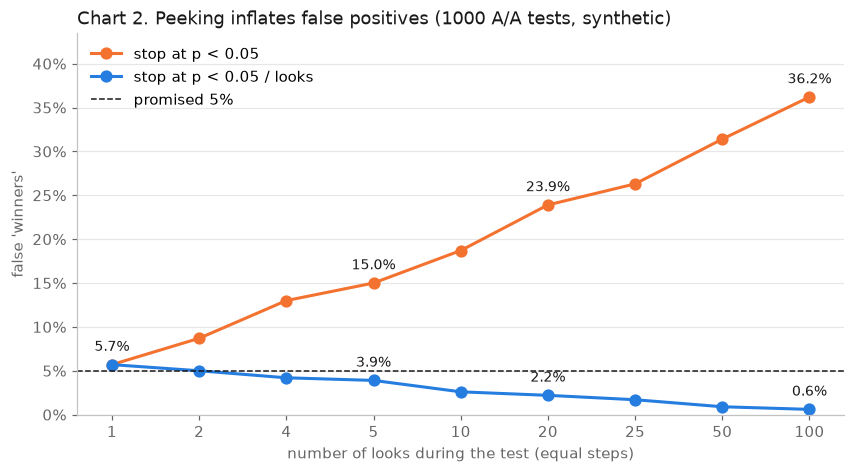

In [3]:
LOOKS = [1, 2, 4, 5, 10, 20, 25, 50, 100]
peek = pd.DataFrame({
    "looks": LOOKS,
    "every_n_per_group": [N // k for k in LOOKS],
    "naive_alpha_005": [sim.stopped_significant(running, k, ALPHA).mean() for k in LOOKS],
    "alpha_divided_by_looks": [sim.stopped_significant(running, k, ALPHA / k).mean() for k in LOOKS],
})
print(peek.to_string(index=False, formatters={
    "naive_alpha_005": "{:.1%}".format, "alpha_divided_by_looks": "{:.1%}".format}))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(LOOKS))
for col, color, label in [("naive_alpha_005", ORANGE, "stop at p < 0.05"),
                          ("alpha_divided_by_looks", BLUE, "stop at p < 0.05 / looks")]:
    ax.plot(x, peek[col], color=color, linewidth=2, marker="o", markersize=7, label=label)
    for i in (0, LOOKS.index(5), LOOKS.index(20), len(LOOKS) - 1):
        if col == "alpha_divided_by_looks" and i == 0:
            continue
        ax.annotate(f"{peek[col][i]:.1%}", (x[i], peek[col][i]), textcoords="offset points",
                    xytext=(0, 9), ha="center", color=INK, fontsize=9)
ax.axhline(ALPHA, color=INK, linewidth=1, linestyle="--", label="promised 5%")
ax.set_xticks(x, LOOKS)
ax.set_ylim(0, peek.naive_alpha_005.max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set(xlabel="number of looks during the test (equal steps)", ylabel="false 'winners'",
       title="Chart 2. Peeking inflates false positives (1000 A/A tests, synthetic)")
ax.legend(loc="upper left")
plt.show()

**Висновок:** якщо перевіряти результат 20 разів і зупинятися на першому p < 0,05, хибна «перемога» трапляється у 23,9% тестів замість 5% (при 100 переглядах у 36,2%), а поділ α на кількість переглядів тримає частку близько 5% або нижче, але з надлишковою обережністю (2,2% при 20 переглядах), яка коштує потужності.

## 3. Множинні порівняння: 20 незалежних метрик без ефекту

1000 експериментів, у кожному 20 незалежних бінарних метрик з однаковою конверсією в обох групах. Припущення спрощене: реальні метрики зазвичай корелюють.

            mean false positives per experiment  experiments with at least one  total among 20 000 metrics
raw                                       1.001                          0.636                      1001.0
bonferroni                                0.047                          0.046                        47.0
holm                                      0.047                          0.046                        47.0
theory without correction: mean 1.00, at least one 64.2%


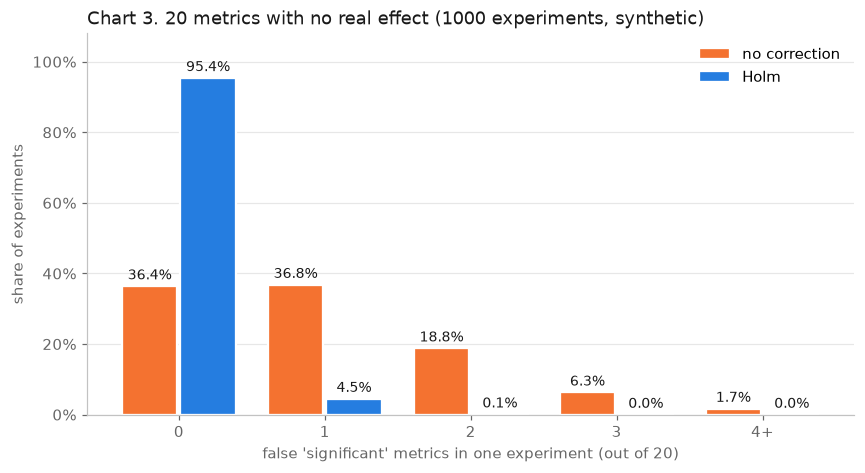

In [4]:
M = 20
rng = np.random.default_rng(42)
x1 = rng.binomial(N, P_ALL, size=(N_SIM, M))
x2 = rng.binomial(N, P_ALL, size=(N_SIM, M))
counts = sim.false_positive_counts(sim.two_proportion_pvalues(x1, N, x2, N), ALPHA)

multi = pd.DataFrame({
    name: {"mean false positives per experiment": c.mean(),
           "experiments with at least one": (c > 0).mean(),
           "total among 20 000 metrics": c.sum()}
    for name, c in counts.items()
}).T
print(multi.round(3).to_string())
print(f"theory without correction: mean {M * ALPHA:.2f}, at least one {1 - (1 - ALPHA) ** M:.1%}")

labels = ["0", "1", "2", "3", "4+"]
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(labels))
for offset, (name, color, label) in zip((-0.2, 0.2), [("raw", ORANGE, "no correction"),
                                                       ("holm", BLUE, "Holm")]):
    c = np.minimum(counts[name], 4)
    shares = np.bincount(c, minlength=5) / N_SIM
    ax.bar(x + offset, shares, width=0.38, color=color, label=label, edgecolor="white", linewidth=1.5)
    for xi, s in zip(x + offset, shares):
        ax.text(xi, s + 0.01, f"{s:.1%}", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set(xlabel="false 'significant' metrics in one experiment (out of 20)", ylabel="share of experiments",
       title="Chart 3. 20 metrics with no real effect (1000 experiments, synthetic)")
ax.legend(loc="upper right")
plt.show()

**Висновок:** без поправки в середньому одна з 20 метрик виявляється «значущою» випадково і 63,6% експериментів мають хоча б одну хибну знахідку (теорія 64,2%), а з Holm або Bonferroni таких експериментів лише 4,6%.

## 4. Power: симуляція проти формули

Базова конверсія = контрольна група (0,573%), як у кроці 6. Для кожного приросту й розміру групи генеруємо 10 000 тестів зі **справжнім** ефектом і рахуємо, в якій частці z-тест дав p < 0,05.

largest |empirical - analytic|: 0.011
 uplift_pp  n_per_group  empirical  analytic
       0.2        21300     0.7128  0.716414
       0.3        21300     0.9587  0.956853
       0.5        21300     0.9999  0.999934


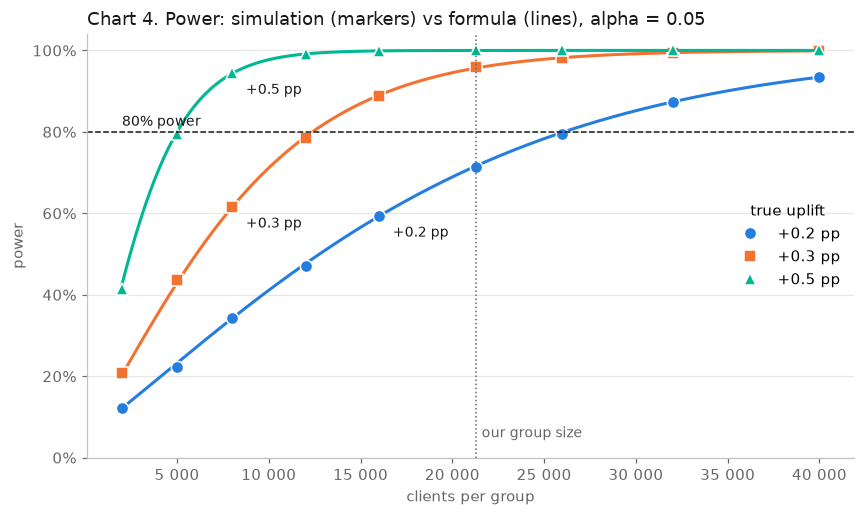

In [5]:
UPLIFTS = [0.002, 0.003, 0.005]
SIZES = [2_000, 5_000, 8_000, 12_000, 16_000, 21_300, 26_000, 32_000, 40_000]
rng = np.random.default_rng(42)
power = pd.DataFrame([
    {"uplift_pp": 100 * u, "n_per_group": n,
     "empirical": sim.empirical_power(rng, P_CONTROL, u, n),
     "analytic": sim.analytic_power(P_CONTROL, u, n)}
    for u in UPLIFTS for n in SIZES
])
print("largest |empirical - analytic|:", f"{(power.empirical - power.analytic).abs().max():.3f}")
print(power[power.n_per_group == N].to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
grid = np.linspace(SIZES[0], SIZES[-1], 200)
for u, color, marker in zip(UPLIFTS, [BLUE, ORANGE, AQUA], ["o", "s", "^"]):
    part = power[power.uplift_pp == 100 * u]
    label = f"+{100 * u:.1f} pp"
    ax.plot(grid, [sim.analytic_power(P_CONTROL, u, n) for n in grid], color=color, linewidth=2)
    ax.plot(part.n_per_group, part.empirical, linestyle="none", marker=marker, markersize=8,
            color=color, markeredgecolor="white", label=label)
    at = {0.002: 16_000, 0.003: 8_000, 0.005: 8_000}[u]
    ax.annotate(label, (at, sim.analytic_power(P_CONTROL, u, at)), textcoords="offset points",
                xytext=(9, -11), va="center", color=INK, fontsize=9)
ax.axhline(0.8, color=INK, linewidth=1, linestyle="--")
ax.text(SIZES[0], 0.815, "80% power", color=INK, fontsize=9)
ax.axvline(N, color=MUTED, linewidth=1, linestyle=":")
ax.text(N + 300, 0.05, "our group size", color=MUTED, fontsize=9)
ax.set_ylim(0, 1.04)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
ax.set(xlabel="clients per group", ylabel="power",
       title="Chart 4. Power: simulation (markers) vs formula (lines), alpha = 0.05")
ax.legend(loc="center right", title="true uplift")
plt.show()

In [6]:
# The sample sizes from step 6 / design document should give about 80% power in simulation.
rng = np.random.default_rng(43)
check = pd.DataFrame([
    {"uplift_pp": 100 * u, "alpha": round(a, 4),
     "n_per_group": (n := ab.sample_size_two_proportions(P_CONTROL, u, alpha=a)),
     "empirical_power": sim.empirical_power(rng, P_CONTROL, u, n, n_sim=100_000, alpha=a)}
    for a in (ALPHA, ALPHA / 3) for u in UPLIFTS
])
print(check.to_string(index=False))

 uplift_pp  alpha  n_per_group  empirical_power
       0.2 0.0500        26074          0.80033
       0.3 0.0500        12377          0.79989
       0.5 0.0500         5003          0.79746
       0.2 0.0167        34778          0.79860
       0.3 0.0167        16509          0.79690
       0.5 0.0167         6673          0.79665


**Висновок:** симуляція збігається з формулою з кроку 6 (найбільша розбіжність 1,1 п.п. потужності, а на розмірах вибірки з дизайн-документа виходить 79,7–80,0%), тож із 21 300 клієнтів на групу приріст +0,3 п.п. виявляється приблизно у 96% випадків, а +0,2 п.п. лише у 71% (α = 0,05 без поправки).

## 5. SRM: зламана рандомізація (опційно)

Клієнтів ділять 50/50, справжнього ефекту немає, але в тестовій групі частина **непокупців** губиться (наприклад, через помилку логування неактивних клієнтів). SRM-тест (chi-square на розміри груп) вважаємо спрацьованим при p < 0,001.

In [7]:
rng = np.random.default_rng(42)
srm = pd.DataFrame([sim.broken_randomization(rng, P_ALL, N, q) for q in (0.0, 0.01, 0.02, 0.05, 0.10, 0.20)])
print(srm.to_string(index=False, formatters={
    "drop_share": "{:.0%}".format, "mean_diff": lambda v: f"{100 * v:+.3f} pp",
    "false_win_share": "{:.1%}".format, "significant_share": "{:.1%}".format,
    "srm_detected_share": "{:.1%}".format}))

drop_share mean_diff false_win_share significant_share srm_detected_share
        0% +0.001 pp            2.8%              5.2%               0.1%
        1% +0.010 pp            3.0%              5.0%               1.2%
        2% +0.019 pp            4.3%              5.7%              10.4%
        5% +0.048 pp            7.2%              7.8%              97.0%
       10% +0.099 pp           17.1%             17.3%             100.0%
       20% +0.221 pp           57.9%             57.9%             100.0%


**Висновок:** втрата 5% непокупців у тестовій групі створює фіктивний приріст +0,048 п.п. і підвищує частку хибних «перемог» з 2,8% до 7,2%, і SRM-тест ловить таку поломку у 97% випадків, але втрату 1–2% здебільшого пропускає (виявляє лише 1–10% випадків), тому пройдений SRM-тест не доводить, що рандомізація ідеальна.

## Підсумок

Усе нижче отримано на синтетичних даних.

| Симуляція | Результат | Що це означає для аналізу |
|---|---|---|
| A/A, 1000 тестів | 5,7% хибних «перемог» (ДІ 4,3–7,3%) | z-тест тримає заявлений рівень 5% |
| Peeking, 20 переглядів | 23,9% замість 5% | горизонт тесту треба фіксувати заздалегідь або застосовувати послідовні методи |
| 20 метрик без ефекту | хоча б одна хибна: 63,6% без поправки, 4,6% з Holm | одна primary-метрика та поправка Holm у кроці 6 виправдані |
| Power | симуляція ≈ формула (розбіжність ≤ 1,1 п.п.) | розрахункам розміру вибірки з кроку 6 можна довіряти |
| Втрата непокупців | 5% втрат: SRM виявляє у 97%, 2%: лише у 10% | SRM-тест потрібен, але малі поломки він пропускає |

У реальних даних SRM-тест пройдений (p = 0,90, `01_eda.ipynb`). Чи дивились на результати під час самої кампанії 2008 року, з датасету дізнатися неможливо. Поділ α на кількість переглядів тут показано лише як простий захист; точніші методи (наприклад, O'Brien–Fleming) у цьому проєкті не розглядаються.